# ConvNeXt-V2 Fine-Tune for a Kaggle-Style Image Competition

**Goal:** fine-tune a pretrained vision backbone for a 20-class Kaggle-style image classification competition.
**Dataset:** the same 20-class image domain as the baseline CNN project, with a held-out competition test set.
**Approach:** fine-tune a pretrained ConvNeXt-V2 Tiny backbone (`timm`), apply several augmentation variants, and combine them with test-time augmentation and model-soup ensembling.
**Headline result:** the best submission used a greedy model soup + 4-view TTA, reaching 83.65% validation accuracy — ahead of four other ensembling strategies tried. See `README.md` and `../../docs/RESULTS.md`.

*Built as part of Monash University FIT5215 Deep Learning (2026).*


# ConvNeXt-V2 Tiny Fine-Tuning for Kaggle Animal Classification

**Author:** Rahul Bhatt

This notebook is my Kaggle submission pipeline, trained on Google Colab with a T4 GPU.

For the labelled Animal dataset I reuse a lot of what worked in my earlier from-scratch CNN notebook (Mixup, CutMix, warmup + cosine, label smoothing, EMA, ensemble), but instead of training a CNN from scratch I fine-tune a pretrained **ConvNeXt-V2 Tiny** from `timm`. The images are only 64×64 originally, so I resize to 224×224 to match the pretrained weights.

A full run (`RUN_MODE='full'`) is roughly 3–6 hours on a T4.

## Setup notes

I ran this on Colab:

1. Runtime → GPU (T4).
2. Put `Animals_Dataset.zip` and `test_set.zip` on my Drive under `FIT5215_Kaggle_A1` (the unit gdown links kept hitting the download quota).
3. Mount Drive in the imports cell if `SAVE_TO_DRIVE=True`, otherwise just keep the zips in `/content`.

There are about 9.5k labelled training images across 20 classes, and 11,681 unlabelled test images. The Kaggle CSV needs columns `ID,Label`.


In [1]:
from __future__ import annotations

import copy
import os
import random
import subprocess
import sys
import zipfile
from pathlib import Path

# packages needed for this notebook
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm', 'gdown', 'scikit-learn'])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from IPython.display import display
from PIL import Image
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

IN_COLAB = Path('/content').is_dir()
SEED = 2026
ROOT = Path('/content') if IN_COLAB else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

# copy checkpoints to Drive if I want them to survive a Colab disconnect
SAVE_TO_DRIVE = IN_COLAB  # only mount/copy on Colab
DRIVE_CKPT_DIR = Path('/content/drive/MyDrive/FIT5215_Kaggle_A1')


def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True
        torch.backends.cudnn.deterministic = False


seed_everything(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('IN_COLAB:', IN_COLAB)
print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    print(f'GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
elif device.type == 'cpu':
    print('No GPU detected — switch Colab runtime to GPU if this is meant to be a full run.')
elif device.type == 'mps':
    print('Using Apple MPS. Full RUN_MODE can take ~12–20h here; use RUN_MODE="fast" to smoke-test.')

if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_CKPT_DIR.mkdir(parents=True, exist_ok=True)
    print('Checkpoints will also be copied to:', DRIVE_CKPT_DIR)


IN_COLAB: False
Working directory: [redacted-path]
PyTorch: 2.11.0
Device: mps
Using Apple MPS. Full RUN_MODE can take ~12–20h here; use RUN_MODE="fast" to smoke-test.


/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Training data

I load `Animals_Dataset.zip` (~600MB) and extract it to `FIT5215_Dataset`.

On Colab the unit Drive download often hits quota, so I upload my own copy from
`~/Downloads/Animals_Dataset_v1.zip`. If the zip is missing, the next cell opens
an upload dialog (or looks on my Drive under `FIT5215_Kaggle_A1`).


In [2]:
import shutil
import zipfile

# Prefer a zip I already uploaded; unit Drive links often hit download quota.
PRIMARY_TRAIN_URL = '[redacted-drive-link]
BACKUP_TRAIN_URL = '[redacted-drive-link]


def _is_train_zip(path: Path) -> bool:
    if not path.is_file():
        return False
    try:
        size = path.stat().st_size
    except OSError:
        return False
    if size < 1_000_000:
        return False
    name = path.name.lower().replace(' ', '_')
    return 'animal' in name and name.endswith('.zip') and 'test' not in name


def _find_uploaded_train_zip() -> Path | None:
    for path in sorted(ROOT.glob('*.zip')):
        if _is_train_zip(path):
            return path
    if not IN_COLAB:
        return None

    if DRIVE_CKPT_DIR.is_dir():
        for path in sorted(DRIVE_CKPT_DIR.glob('*.zip')):
            if _is_train_zip(path):
                return path

    mydrive = Path('/content/drive/MyDrive')
    if mydrive.is_dir():
        print('Searching MyDrive for *animal*.zip ...')
        for path in mydrive.rglob('*.zip'):
            if _is_train_zip(path):
                print(f'Found: {path} ({path.stat().st_size / 1e6:.1f} MB)')
                return path
    return None


def _ensure_train_archive() -> Path | None:
    found = _find_uploaded_train_zip()
    if found is None:
        return None
    if found.resolve() != TRAIN_ARCHIVE.resolve():
        print(f'Found training zip at {found} → copying to {TRAIN_ARCHIVE}')
        shutil.copy2(found, TRAIN_ARCHIVE)
    else:
        print('Using training zip:', TRAIN_ARCHIVE)
    return TRAIN_ARCHIVE


def _colab_upload_train_zip() -> bool:
    """Open the Colab file picker so I can upload Animals_Dataset.zip (~600MB)."""
    if not IN_COLAB:
        return False
    print(
        'Upload Animals_Dataset.zip now.\\n'
        'On your Mac use the real file:\\n'
        '  ~/Downloads/Animals_Dataset_v1.zip\\n'
        '(about 613 MB — wait until the upload finishes)'
    )
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        src = Path(name)
        if src.suffix.lower() != '.zip':
            continue
        if TRAIN_ARCHIVE.exists() and src.resolve() != TRAIN_ARCHIVE.resolve():
            TRAIN_ARCHIVE.unlink()
        if src.resolve() != TRAIN_ARCHIVE.resolve():
            shutil.move(str(src), str(TRAIN_ARCHIVE))
        print('Saved upload as', TRAIN_ARCHIVE, f'({TRAIN_ARCHIVE.stat().st_size / 1e6:.1f} MB)')
        return TRAIN_ARCHIVE.is_file() and TRAIN_ARCHIVE.stat().st_size > 1_000_000
    return False


def _download_train_archive() -> None:
    import gdown
    print('Trying unit Drive links ...')
    try:
        gdown.download(PRIMARY_TRAIN_URL, str(TRAIN_ARCHIVE), quiet=False, fuzzy=True)
    except Exception as exc:
        print('Primary download failed:', exc)
        print('Trying backup link ...')
        try:
            gdown.download(BACKUP_TRAIN_URL, str(TRAIN_ARCHIVE), quiet=False, fuzzy=True)
        except Exception:
            print('Unit Drive links failed (quota). Falling back to manual upload.')
    if TRAIN_ARCHIVE.is_file() and TRAIN_ARCHIVE.stat().st_size > 1_000_000:
        return
    if IN_COLAB and _colab_upload_train_zip():
        return
    raise FileNotFoundError(
        'No training zip available. Upload ~/Downloads/Animals_Dataset_v1.zip '
        'to Colab (/content) or to Drive/FIT5215_Kaggle_A1, then re-run this cell.'
    )


if TRAIN_DIR.is_dir() and any(TRAIN_DIR.iterdir()):
    print('Training data already present:', TRAIN_DIR.resolve())
else:
    print('Drive mounted?', Path('/content/drive/MyDrive').is_dir())
    print('Zips in /content:', [p.name for p in ROOT.glob('*.zip')])
    if DRIVE_CKPT_DIR.is_dir():
        print('Files in Drive/FIT5215_Kaggle_A1:', [p.name for p in DRIVE_CKPT_DIR.iterdir()])
    archive = _ensure_train_archive()
    if archive is None or not archive.is_file():
        _download_train_archive()
        archive = TRAIN_ARCHIVE
    print('Extracting', archive, '...')
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(ROOT)
    if not TRAIN_DIR.is_dir():
        for candidate in ROOT.rglob('birds'):
            if candidate.is_dir():
                maybe = candidate.parent
                if (maybe / 'dogs').is_dir() or (maybe / 'cats').is_dir():
                    if maybe != TRAIN_DIR and not TRAIN_DIR.exists():
                        maybe.rename(TRAIN_DIR)
                    break
    if not TRAIN_DIR.is_dir():
        raise FileNotFoundError(f'Could not find {TRAIN_DIR} after unzip.')
    print('Extracted training data to:', TRAIN_DIR.resolve())

print('Training data ready:', TRAIN_DIR)
print('Class folders:', len([p for p in TRAIN_DIR.iterdir() if p.is_dir()]))


Training data already present: [redacted-path]
Training data ready: [redacted-path]
Class folders: 20


## 2. Test set and submission template

Same idea for `test_set.zip`. After unzipping I expect:

- `test_set/test_dataset/` with 11,681 images named `{id}_animal.jpeg`
- `test_set/my_solution.csv` as the submission template

I check the ID range and row count here before training so I do not find a packaging mistake later.


In [3]:
import shutil

EXPECTED_TEST_IMAGES = 11_681


def _find_test_zip() -> Path | None:
    search_dirs = [ROOT]
    if IN_COLAB:
        search_dirs.extend([
            DRIVE_CKPT_DIR,
            Path('/content/drive/MyDrive'),
            Path('/content/drive/MyDrive/Colab Notebooks'),
        ])
    for folder in search_dirs:
        if not folder.is_dir():
            continue
        for path in [folder / 'test_set.zip', *sorted(folder.glob('*.zip')), *sorted(folder.glob('*/*.zip'))]:
            if path.is_file() and 'test' in path.name.lower() and path.stat().st_size > 100_000:
                return path
    return None


if IN_COLAB and not TEST_ARCHIVE.is_file() and not (TEST_DIR.is_dir() and SUBMISSION_TEMPLATE.is_file()):
    found = _find_test_zip()
    if found is not None:
        print(f'Found test zip at {found} → copying to {TEST_ARCHIVE}')
        shutil.copy2(found, TEST_ARCHIVE)
    else:
        print('test_set.zip not found — opening upload dialog ...')
        from google.colab import files
        uploaded = files.upload()
        for name in uploaded:
            src = Path(name)
            if src.suffix.lower() == '.zip':
                dest = ROOT / 'test_set.zip'
                if src.resolve() != dest.resolve():
                    if dest.exists():
                        dest.unlink()
                    src.rename(dest)
                print('Using', dest)
                break

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    if not TEST_ARCHIVE.is_file():
        found = _find_test_zip()
        if found is not None and found.resolve() != TEST_ARCHIVE.resolve():
            shutil.copy2(found, TEST_ARCHIVE)
        if not TEST_ARCHIVE.is_file():
            raise FileNotFoundError(
                'Could not find test_set.zip in /content or Drive/FIT5215_Kaggle_A1.'
            )
    print('Extracting', TEST_ARCHIVE, '...')
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), 'The ZIP must contain a top-level folder named test_set.'
assert TEST_DIR.is_dir(), 'The test_set folder must contain the test_dataset image folder.'
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), 'The test_set folder must contain my_solution.csv.'
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())


Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Datasets and transforms

I keep a fixed stratified 85/15 train/val split with `SEED=2026` so every experiment sees the same validation images.

Because I use a pretrained ConvNeXt, inputs are resized to 224×224 and normalised with ImageNet mean/std.

For Baseline / Mixup / CutMix I use the same style of augmentation as Part 3 (random crop, flip, rotation, affine, ColorJitter, RandomErasing). I also train one extra model where the middle augments are replaced by `TrivialAugmentWide`, just to see if that helps.

Val and test use a plain resize. For TTA later I also build flip / zoom-crop / small-rotation views.


In [4]:
EXPECTED_CLASS_NAMES = [
    'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
    'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
    'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
    'spiders', 'vases',
]
CLASS_NAME_CORRECTIONS = {'butterfiles': 'butterflies'}

IMAGE_SIZE = 224
MEAN = (0.485, 0.456, 0.406)  # ImageNet stats for the pretrained backbone
STD = (0.229, 0.224, 0.225)
VALIDATION_FRACTION = 0.15

# aug used for Baseline / Mixup / CutMix
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(12),
    transforms.RandomAffine(0, shear=8, scale=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12)),
])
# alternate aug: TrivialAugmentWide instead of rotation/affine/ColorJitter
train_transform_trivial = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 32, IMAGE_SIZE + 32)),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.12)),
])
evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
tta_hflip_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Zoom a bit: resize 256, then center crop 224
tta_crop_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Fixed +10 degree rotation for TTA
tta_rotate_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(lambda img: transforms.functional.rotate(img, angle=10, fill=0)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

index_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = [
    CLASS_NAME_CORRECTIONS.get(name, name) for name in index_dataset.classes
]
if class_names != EXPECTED_CLASS_NAMES:
    raise RuntimeError(f'Unexpected training class order: {class_names}')
targets = np.asarray(index_dataset.targets, dtype=np.int64)
rng = np.random.default_rng(SEED)
train_indices = []
validation_indices = []
for class_index in range(len(class_names)):
    class_indices = np.flatnonzero(targets == class_index)
    rng.shuffle(class_indices)
    validation_count = max(1, int(round(len(class_indices) * VALIDATION_FRACTION)))
    validation_indices.extend(class_indices[:validation_count].tolist())
    train_indices.extend(class_indices[validation_count:].tolist())
train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

training_augmented = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
training_augmented_trivial = datasets.ImageFolder(TRAIN_DIR, transform=train_transform_trivial)
training_evaluation = datasets.ImageFolder(TRAIN_DIR, transform=evaluation_transform)
train_dataset = Subset(training_augmented, train_indices)
train_dataset_trivial = Subset(training_augmented_trivial, train_indices)
train_evaluation_dataset = Subset(training_evaluation, train_indices)
validation_dataset = Subset(training_evaluation, validation_indices)

class KaggleTestDataset(Dataset):
    def __init__(self, paths: list[Path], transform):
        self.paths = paths
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int):
        path = self.paths[index]
        test_id = int(path.name.split('_', 1)[0])
        with Image.open(path) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, test_id

test_dataset = KaggleTestDataset(test_paths, evaluation_transform)
test_dataset_hflip = KaggleTestDataset(test_paths, tta_hflip_transform)
test_dataset_crop = KaggleTestDataset(test_paths, tta_crop_transform)
test_dataset_rotate = KaggleTestDataset(test_paths, tta_rotate_transform)

# same TTA views on val — reuse training_evaluation sample order via transform swap
validation_eval_hflip = datasets.ImageFolder(TRAIN_DIR, transform=tta_hflip_transform)
validation_eval_crop = datasets.ImageFolder(TRAIN_DIR, transform=tta_crop_transform)
validation_eval_rotate = datasets.ImageFolder(TRAIN_DIR, transform=tta_rotate_transform)
# keep class/sample order identical to training_evaluation
validation_eval_hflip.samples = list(training_evaluation.samples)
validation_eval_crop.samples = list(training_evaluation.samples)
validation_eval_rotate.samples = list(training_evaluation.samples)
validation_eval_hflip.targets = list(training_evaluation.targets)
validation_eval_crop.targets = list(training_evaluation.targets)
validation_eval_rotate.targets = list(training_evaluation.targets)
validation_dataset_hflip = Subset(validation_eval_hflip, validation_indices)
validation_dataset_crop = Subset(validation_eval_crop, validation_indices)
validation_dataset_rotate = Subset(validation_eval_rotate, validation_indices)

print('Classes:', class_names)
print(f'Train images: {len(train_dataset):,} | Val images: {len(validation_dataset):,}')
print(f'Model input size: {IMAGE_SIZE}x{IMAGE_SIZE}')
print('Train aug A: rotation/affine/ColorJitter')
print('Train aug B: TrivialAugmentWide')


Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']
Train images: 8,047 | Val images: 1,419
Model input size: 224x224
Train aug A: rotation/affine/ColorJitter
Train aug B: TrivialAugmentWide


In [5]:
# Mixup/CutMix need extra GPU memory, so 64 is safer on T4 than 128
if device.type == 'cuda':
    BATCH_SIZE = 64
    NUM_WORKERS = min(2, os.cpu_count() or 1)
elif __import__('sys').platform == 'darwin':
    BATCH_SIZE = 32  # Mixup on MPS — 32 is safer than 64 on unified memory
    NUM_WORKERS = 0  # avoid multiprocessing pickle issues on Mac
else:
    BATCH_SIZE = 64
    NUM_WORKERS = min(2, os.cpu_count() or 1)
pin_memory = device.type == 'cuda'
print(f'BATCH_SIZE={BATCH_SIZE}, NUM_WORKERS={NUM_WORKERS}, pin_memory={pin_memory}')
loader_generator = torch.Generator().manual_seed(SEED)

def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Per-class counts from the full ImageFolder (index_dataset.targets)
full_targets = np.asarray(index_dataset.targets, dtype=np.int64)
full_class_counts = np.bincount(full_targets, minlength=len(class_names))
print('Per-class image counts (index_dataset.targets):')
for name, count in zip(class_names, full_class_counts):
    print(f'  {name:12s}: {int(count)}')
print(
    f'min={int(full_class_counts.min())}, '
    f'median={float(np.median(full_class_counts)):.1f}, '
    f'max={int(full_class_counts.max())}'
)

# If the smallest class is under 90% of the median, I treat it as imbalanced
median_count = float(np.median(full_class_counts))
USE_WEIGHTED_SAMPLER = bool(full_class_counts.min() < 0.90 * median_count)
print(f'USE_WEIGHTED_SAMPLER={USE_WEIGHTED_SAMPLER}')

train_sampler = None
trivial_sampler = None
trivial_loader_generator = torch.Generator().manual_seed(SEED)
if USE_WEIGHTED_SAMPLER:
    from torch.utils.data import WeightedRandomSampler

    # Inverse-frequency weights on the training split only
    train_targets = full_targets[np.asarray(train_indices, dtype=np.int64)]
    train_class_counts = np.bincount(train_targets, minlength=len(class_names)).astype(np.float64)
    train_class_counts[train_class_counts == 0] = 1.0
    sample_weights = torch.as_tensor(
        1.0 / train_class_counts[train_targets], dtype=torch.double
    )
    train_sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
        generator=loader_generator,
    )
    trivial_sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
        generator=trivial_loader_generator,
    )
    print('Classes are uneven — using WeightedRandomSampler.')
else:
    print('Classes look fine — normal shuffle.')

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=(train_sampler is None),
    sampler=train_sampler,
    generator=loader_generator if train_sampler is None else None,
    worker_init_fn=seed_worker,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    drop_last=True,
)
# Separate loader so the TrivialAugmentWide run does not change Baseline/Mixup/CutMix
train_loader_trivial = DataLoader(
    train_dataset_trivial,
    batch_size=BATCH_SIZE,
    shuffle=(trivial_sampler is None),
    sampler=trivial_sampler,
    generator=trivial_loader_generator if trivial_sampler is None else None,
    worker_init_fn=seed_worker,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    drop_last=True,
)
train_evaluation_loader = DataLoader(
    train_evaluation_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_loader_hflip = DataLoader(
    test_dataset_hflip, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_loader_crop = DataLoader(
    test_dataset_crop, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
test_loader_rotate = DataLoader(
    test_dataset_rotate, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
validation_loader_hflip = DataLoader(
    validation_dataset_hflip, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
validation_loader_crop = DataLoader(
    validation_dataset_crop, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
validation_loader_rotate = DataLoader(
    validation_dataset_rotate, batch_size=BATCH_SIZE * 2, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
)
print(f'Train: {len(train_dataset):,}')
print(f'Validation: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')
print('Also built train_loader_trivial')


BATCH_SIZE=32, NUM_WORKERS=0, pin_memory=False
Per-class image counts (index_dataset.targets):
  birds       : 512
  bottles     : 432
  breads      : 432
  butterflies : 500
  cakes       : 432
  cats        : 501
  chickens    : 500
  cows        : 500
  dogs        : 501
  ducks       : 496
  elephants   : 500
  fishes      : 500
  handguns    : 448
  horses      : 500
  lions       : 500
  lipsticks   : 400
  seals       : 448
  snakes      : 496
  spiders     : 500
  vases       : 368
min=368, median=500.0, max=512
USE_WEIGHTED_SAMPLER=True
Classes are uneven — using WeightedRandomSampler.
Train: 8,047
Validation: 1,419
Test: 11,681
Also built train_loader_trivial


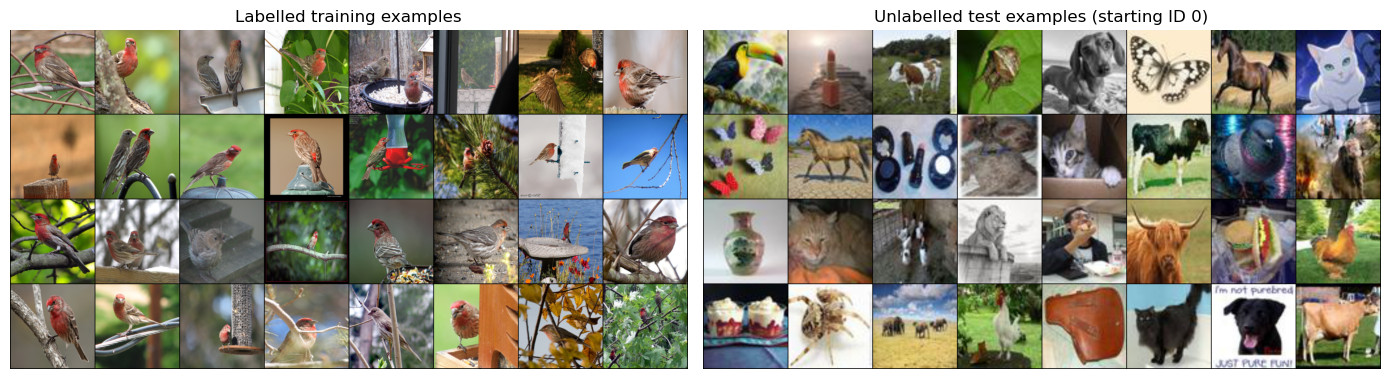

Example training label: birds


In [6]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

## 4. Model

I use pretrained **ConvNeXt-V2 Tiny** from `timm` (`convnextv2_tiny.fcmae_ft_in22k_in1k`) with `num_classes=20` and head dropout `drop_rate=0.3`.

`make_model()` builds a fresh copy each time so Baseline, Mixup, CutMix and TrivialAug do not share weights.


In [7]:
TIMM_MODEL_NAME = 'convnextv2_tiny.fcmae_ft_in22k_in1k'
HEAD_DROP_RATE = 0.3  # same idea as the old torchvision head dropout


class TimmClassifier(nn.Module):
    """timm ConvNeXt-V2 Tiny, 20 classes."""

    def __init__(self, num_classes: int, drop_rate: float = HEAD_DROP_RATE):
        super().__init__()
        self.backbone = timm.create_model(
            TIMM_MODEL_NAME,
            pretrained=True,
            num_classes=num_classes,
            drop_rate=drop_rate,
        )

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        return self.backbone(inputs)


def make_model() -> TimmClassifier:
    return TimmClassifier(num_classes=len(class_names)).to(device)


model = make_model()

# check how timm names the head (for the backbone/head LR split)
print('Head parameter names:')
head_prefixes = sorted({
    name.split('.')[0]
    for name, _ in model.backbone.named_parameters()
})
print('Top-level parameter groups:', head_prefixes)
for name, _ in model.backbone.named_parameters():
    if name.startswith('head'):
        print('  head param:', name)

trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_parameters = sum(p.numel() for p in model.parameters())
print(model)
print('Classification head:')
print(model.backbone.head)
head_drop = getattr(model.backbone.head, 'drop', None)
print(f'Head dropout layer: {head_drop}')
if head_drop is None or float(getattr(head_drop, 'p', 0.0)) <= 0:
    raise RuntimeError('Expected Dropout before the final linear layer (drop_rate=0.3).')
print(f'Total parameters: {total_parameters:,}')
print(f'Trainable parameters: {trainable_parameters:,}')
print(f'Using timm pretrained {TIMM_MODEL_NAME} with drop_rate={HEAD_DROP_RATE}')


Head parameter names:
Top-level parameter groups: ['head', 'stages', 'stem']
  head param: head.norm.weight
  head param: head.norm.bias
  head param: head.fc.weight
  head param: head.fc.bias
TimmClassifier(
  (backbone): ConvNeXt(
    (stem): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (stages): Sequential(
      (0): ConvNeXtStage(
        (downsample): Identity()
        (blocks): Sequential(
          (0): ConvNeXtBlock(
            (conv_dw): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
            (norm): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
            (mlp): GlobalResponseNormMlp(
              (fc1): Linear(in_features=96, out_features=384, bias=True)
              (act): GELU()
              (drop1): Dropout(p=0.0, inplace=False)
              (grn): GlobalResponseNorm()
              (fc2): Linear(in_features=384, out_featur

## 5. Training

I mostly copy the training recipe from Part 3 onto this backbone:

- Mixup or CutMix with α=0.1 on about half the batches (the other half stay normal CE)
- label smoothing 0.1
- linear warmup, then cosine decay
- smaller LR on the backbone, larger LR on the head
- EMA with decay 0.999 updated every training step; at the end I keep EMA or the best checkpoint, whichever is better on val

Before the long 35-epoch runs I do a short Mixup probe (12 epochs, no early stopping): one run with the backbone trainable from the start, and one with the backbone frozen for the first 3 epochs. If freeze-first is clearly better by the end of the probe, I turn that on for all four full runs.


In [8]:
MIX_ALPHA = 0.1
MIX_PROB = 0.5       # mix only half the batches
WARMUP_EPOCHS = 3
EMA_DECAY = 0.999

from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn


def mixup_data(images, labels, alpha: float = MIX_ALPHA):
    if alpha <= 0:
        return images, labels, labels, 1.0
    lam = float(np.random.beta(alpha, alpha))
    index = torch.randperm(images.size(0), device=images.device)
    mixed = lam * images + (1.0 - lam) * images[index]
    return mixed, labels, labels[index], lam


def cutmix_data(images, labels, alpha: float = MIX_ALPHA):
    if alpha > 0:
        lam = float(np.random.beta(alpha, alpha))
    else:
        lam = 1.0
    index = torch.randperm(images.size(0), device=images.device)
    _, _, height, width = images.shape
    cut_rat = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(width * cut_rat), int(height * cut_rat)
    cx, cy = np.random.randint(width), np.random.randint(height)
    x1, y1 = np.clip(cx - cut_w // 2, 0, width), np.clip(cy - cut_h // 2, 0, height)
    x2, y2 = np.clip(cx + cut_w // 2, 0, width), np.clip(cy + cut_h // 2, 0, height)
    mixed = images.clone()
    mixed[:, :, y1:y2, x1:x2] = images[index, :, y1:y2, x1:x2]
    lam = 1.0 - ((x2 - x1) * (y2 - y1) / float(width * height))
    return mixed, labels, labels[index], lam


def mix_criterion(loss_function, logits, y_a, y_b, lam: float):
    return lam * loss_function(logits, y_a) + (1.0 - lam) * loss_function(logits, y_b)


# timm uses `head` here (torchvision used `classifier`).
# After wrapping: backbone.head.*
HEAD_SUBMODULE = 'head'


def _is_head_param(name: str) -> bool:
    return (
        f'.{HEAD_SUBMODULE}.' in name
        or name.startswith(f'{HEAD_SUBMODULE}.')
        or name.startswith(f'backbone.{HEAD_SUBMODULE}')
    )


def set_backbone_trainable(model, trainable: bool) -> None:
    """Freeze/unfreeze everything that is not the classification head."""
    for name, param in model.named_parameters():
        if not _is_head_param(name):
            param.requires_grad = trainable


def build_optimizer(model, backbone_lr: float, head_lr: float, weight_decay: float):
    backbone_params, head_params = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if _is_head_param(name):
            head_params.append(param)
        else:
            backbone_params.append(param)
    if not head_params:
        raise RuntimeError(
            f'No head params matched submodule "{HEAD_SUBMODULE}". '
            'Check model.backbone.named_parameters() and fix HEAD_SUBMODULE.'
        )
    param_groups = []
    if backbone_params:
        param_groups.append({'params': backbone_params, 'lr': backbone_lr})
    param_groups.append({'params': head_params, 'lr': head_lr})
    print(
        f'Optimizer split: backbone={len(backbone_params)} tensors, '
        f'head={len(head_params)} tensors'
    )
    return torch.optim.AdamW(param_groups, weight_decay=weight_decay)


def make_warmup_cosine_scheduler(optimizer, num_epochs: int, warmup_epochs: int = WARMUP_EPOCHS):
    warmup_epochs = int(min(warmup_epochs, num_epochs))
    cosine_epochs = max(1, num_epochs - warmup_epochs)
    warmup = torch.optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=1.0 / max(1, warmup_epochs),
        end_factor=1.0,
        total_iters=warmup_epochs,
    )
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cosine_epochs)
    return torch.optim.lr_scheduler.SequentialLR(
        optimizer, schedulers=[warmup, cosine], milestones=[warmup_epochs]
    )


def run_epoch(
    model,
    loader,
    loss_function,
    optimizer=None,
    scaler: GradScaler | None = None,
    mix_fn=None,
    mix_prob: float = MIX_PROB,
    mix_alpha: float = MIX_ALPHA,
    ema_model=None,
):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        labels = labels.to(device=device, dtype=torch.long, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)
            use_mix = mix_fn is not None and (np.random.rand() < mix_prob)
            if use_mix:
                images, targets_a, targets_b, lam = mix_fn(images, labels, mix_alpha)
            use_amp = scaler is not None and scaler.is_enabled()
            with autocast(device_type='cuda', enabled=use_amp):
                logits = model(images)
                if use_mix:
                    loss = mix_criterion(loss_function, logits, targets_a, targets_b, lam)
                else:
                    loss = loss_function(logits, labels)
            if use_amp:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            # decay=0.999 is for per-step EMA — update once per training batch
            if ema_model is not None:
                ema_model.update_parameters(model)
        else:
            with torch.inference_mode():
                with autocast(device_type='cuda', enabled=(device.type == 'cuda')):
                    logits = model(images)
                    loss = loss_function(logits, labels)

        batch_size = labels.size(0)
        total_loss += float(loss.item()) * batch_size
        total_correct += int((logits.argmax(dim=1) == labels).sum())
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


def fit_model(
    model,
    train_loader,
    validation_loader,
    loss_function,
    epochs: int,
    backbone_lr: float,
    head_lr: float,
    weight_decay: float,
    mix_fn=None,
    mix_prob: float = MIX_PROB,
    mix_alpha: float = MIX_ALPHA,
    patience: int | None = 12,
    name: str = 'model',
    ema_decay: float = EMA_DECAY,
    freeze_backbone_epochs: int = 0,
):
    freeze_backbone_epochs = int(max(0, freeze_backbone_epochs))
    if freeze_backbone_epochs > 0:
        set_backbone_trainable(model, False)
        print(f'[{name}] Backbone frozen for first {freeze_backbone_epochs} epoch(s).')

    optimizer = build_optimizer(model, backbone_lr, head_lr, weight_decay)
    scheduler = make_warmup_cosine_scheduler(optimizer, epochs, WARMUP_EPOCHS)
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    # AMP only on CUDA; MPS runs float32 (more stable on Apple GPU)
    scaler = GradScaler('cuda') if device.type == 'cuda' else None
    # EMA weights; decay=0.999 expects a per-step update (done inside run_epoch)
    ema_model = AveragedModel(
        model,
        multi_avg_fn=get_ema_multi_avg_fn(ema_decay),
        use_buffers=True,
    )
    history = []
    best_score = (-1.0, float('-inf'))
    best_state = None
    best_epoch = 0
    epochs_without_improve = 0

    for epoch in range(1, epochs + 1):
        if freeze_backbone_epochs > 0 and epoch == freeze_backbone_epochs + 1:
            set_backbone_trainable(model, True)
            optimizer = build_optimizer(model, backbone_lr, head_lr, weight_decay)
            # fresh cosine over the remaining epochs (warmup already done on the head)
            remaining = max(1, epochs - freeze_backbone_epochs)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=remaining)
            print(f'[{name}] Unfroze backbone at epoch {epoch}; cosine over {remaining} epochs.')

        train_loss, train_accuracy = run_epoch(
            model, train_loader, loss_function, optimizer,
            scaler=scaler, mix_fn=mix_fn, mix_prob=mix_prob, mix_alpha=mix_alpha,
            ema_model=ema_model,
        )
        # val pass: no optimizer, so run_epoch will not touch EMA

        validation_loss, validation_accuracy = run_epoch(model, validation_loader, loss_function)
        scheduler.step()
        backbone_lr_now = float(optimizer.param_groups[0]['lr'])
        head_lr_now = float(optimizer.param_groups[-1]['lr'])
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_accuracy': train_accuracy,
            'validation_loss': validation_loss,
            'validation_accuracy': validation_accuracy,
            'backbone_lr': backbone_lr_now,
            'head_lr': head_lr_now,
        })
        score = (validation_accuracy, -validation_loss)
        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improve = 0
        else:
            epochs_without_improve += 1

        print(
            f'[{name}] Epoch {epoch:02d}/{epochs:02d} | '
            f'train loss {train_loss:.4f}, acc {train_accuracy:.2%} | '
            f'val loss {validation_loss:.4f}, acc {validation_accuracy:.2%} | '
            f'lr b/h {backbone_lr_now:.2e}/{head_lr_now:.2e}'
        )
        if patience is not None and epochs_without_improve >= patience:
            print(f'[{name}] Early stopping at epoch {epoch}.')
            break

    # Keep EMA or best checkpoint — whichever is better on val
    model.load_state_dict(best_state)
    model.to(device)
    _, ckpt_acc = run_epoch(model, validation_loader, loss_function)
    ema_model.to(device)
    _, ema_acc = run_epoch(ema_model, validation_loader, loss_function)
    print(
        f'[{name}] Final pick — best checkpoint val={ckpt_acc:.2%}, '
        f'EMA(decay={ema_decay}) val={ema_acc:.2%}'
    )
    if ema_acc >= ckpt_acc:
        model.load_state_dict(ema_model.module.state_dict())
        chosen_state = copy.deepcopy(model.state_dict())
        chosen_acc = float(ema_acc)
        print(f'[{name}] Using EMA weights.')
    else:
        model.load_state_dict(best_state)
        chosen_state = best_state
        chosen_acc = float(ckpt_acc)
        print(f'[{name}] Using best checkpoint (epoch {best_epoch}).')

    model.to(device)
    return pd.DataFrame(history), chosen_state, best_epoch, chosen_acc


In [9]:

print("Skipping full training — loading convnextv2_part3_ensemble.pt")
_ckpt = ROOT / "convnextv2_part3_ensemble.pt"
assert _ckpt.is_file(), _ckpt
_loaded = torch.load(_ckpt, map_location=device, weights_only=False)
trained_models = {}
for _name, _info in _loaded["models"].items():
    _m = make_model()
    _m.load_state_dict(_info["state_dict"])
    _m.to(device)
    trained_models[_name] = (
        _m,
        float(_info["val_accuracy"]),
        int(_info.get("best_epoch", -1)),
        None,
    )
    print(f"  {_name}: {100 * trained_models[_name][1]:.2f}% (epoch {trained_models[_name][2]})")
FREEZE_BACKBONE_EPOCHS = int(_loaded.get("freeze_backbone_epochs", 0))
ranked = sorted(trained_models.items(), key=lambda item: item[1][1], reverse=True)
ensemble_members = ranked[: min(2, len(ranked))]
best_name, (best_model, best_val, best_epoch, history) = ranked[0]
model = best_model
checkpoint_path = ROOT / "convnextv2_part3_ensemble.pt"
print("Best single model:", best_name, f"{100*best_val:.2f}%")
print("Ensemble members:", [n for n,_ in ensemble_members])


Skipping full training — loading convnextv2_part3_ensemble.pt


  Baseline: 88.51% (epoch 25)


  Mixup: 89.71% (epoch 24)


  CutMix: 97.32% (epoch 15)


  TrivialAug: 98.52% (epoch 13)
Best single model: TrivialAug 98.52%
Ensemble members: ['TrivialAug', 'CutMix']


## Model soup vs softmax ensemble

After the four models finish I also try weight averaging (model soup): top-2, top-3, all four, and a greedy soup that only adds a model if validation accuracy goes up. I compare those against a normal softmax ensemble and use whichever scores best on validation for the submission.


In [10]:
# --- Model soup + softmax ensemble comparison (needs the 4 trained models) ---
REQUIRED_SOUP_MODELS = ['Baseline', 'Mixup', 'CutMix', 'TrivialAug']

# Rebuild trained_models from the ensemble checkpoint if needed (e.g. after a crash past training)
_ckpt = ROOT / 'convnextv2_part3_ensemble.pt'
if (not trained_models or not set(REQUIRED_SOUP_MODELS).issubset(trained_models)) and _ckpt.is_file():
    print('Loading trained models from', _ckpt)
    _loaded = torch.load(_ckpt, map_location=device, weights_only=False)
    trained_models = {}
    for _name, _info in _loaded['models'].items():
        _m = make_model()
        _m.load_state_dict(_info['state_dict'])
        _m.to(device)
        trained_models[_name] = (
            _m,
            float(_info['val_accuracy']),
            int(_info.get('best_epoch', -1)),
            None,
        )
        print(f'  loaded {_name}: {100 * trained_models[_name][1]:.2f}%')
    FREEZE_BACKBONE_EPOCHS = int(_loaded.get('freeze_backbone_epochs', 0))

submission_mode = 'softmax_ensemble'  # default fallback
final_soup_model = None
soup_results = {}

def average_state_dicts(state_dicts: list[dict]) -> dict:
    """Element-wise mean of floating tensors; keep non-floats from the first model."""
    out = {}
    for key in state_dicts[0].keys():
        tensors = [sd[key] for sd in state_dicts]
        if torch.is_floating_point(tensors[0]):
            stacked = torch.stack([t.detach().float().cpu() for t in tensors], dim=0)
            out[key] = stacked.mean(dim=0).to(dtype=tensors[0].dtype)
        else:
            out[key] = tensors[0].detach().cpu().clone()
    return out


@torch.inference_mode()
def validation_accuracy_tta4(model) -> float:
    """Val accuracy with the same 4-view TTA used at test time."""
    loaders = [
        validation_loader,
        validation_loader_hflip,
        validation_loader_crop,
        validation_loader_rotate,
    ]
    model.eval()
    view_probs = []
    labels_ref = None
    for loader in loaders:
        probs_chunks = []
        labels_chunks = []
        for images, labels in loader:
            images = images.to(device=device, dtype=torch.float32, non_blocking=True)
            labels = labels.to(device=device, dtype=torch.long, non_blocking=True)
            with autocast(device_type='cuda', enabled=(device.type == 'cuda')):
                logits = model(images)
            probs_chunks.append(torch.softmax(logits.float(), dim=1).cpu())
            labels_chunks.append(labels.cpu())
        probs = torch.cat(probs_chunks, dim=0)
        labels = torch.cat(labels_chunks, dim=0)
        if labels_ref is None:
            labels_ref = labels
        elif labels.shape != labels_ref.shape:
            raise RuntimeError(
                f'Validation TTA length mismatch: {tuple(labels.shape)} vs {tuple(labels_ref.shape)}'
            )
        view_probs.append(probs)
    probs = torch.stack(view_probs, dim=0).mean(dim=0)
    preds = probs.argmax(dim=1)
    return float((preds == labels_ref).float().mean())


@torch.inference_mode()
def softmax_ensemble_val_accuracy(members: list) -> float:
    """Average softmax probs across models, then 4-view TTA."""
    loaders = [
        validation_loader,
        validation_loader_hflip,
        validation_loader_crop,
        validation_loader_rotate,
    ]
    labels_ref = None
    member_view_probs = []
    for mdl, _score in members:
        mdl.eval()
        view_probs = []
        for loader in loaders:
            probs_chunks, labels_chunks = [], []
            for images, labels in loader:
                images = images.to(device=device, dtype=torch.float32, non_blocking=True)
                labels = labels.to(device=device, dtype=torch.long, non_blocking=True)
                with autocast(device_type='cuda', enabled=(device.type == 'cuda')):
                    logits = mdl(images)
                probs_chunks.append(torch.softmax(logits.float(), dim=1).cpu())
                labels_chunks.append(labels.cpu())
            labels = torch.cat(labels_chunks, dim=0)
            if labels_ref is None:
                labels_ref = labels
            elif labels.shape != labels_ref.shape:
                raise RuntimeError(f'Validation TTA length mismatch')
            view_probs.append(torch.cat(probs_chunks, dim=0))
        member_view_probs.append(torch.stack(view_probs, dim=0).mean(dim=0))
    probs = torch.stack(member_view_probs, dim=0).mean(dim=0)
    preds = probs.argmax(dim=1)
    return float((preds == labels_ref).float().mean())


def make_soup_model(state_dicts: list[dict]) -> nn.Module:
    soup = make_model()
    soup.load_state_dict(average_state_dicts(state_dicts))
    soup.to(device)
    soup.eval()
    return soup


if set(REQUIRED_SOUP_MODELS) <= set(trained_models):
    ranked_for_soup = sorted(
        [(name, trained_models[name][0], float(trained_models[name][1])) for name in REQUIRED_SOUP_MODELS],
        key=lambda item: item[2],
        reverse=True,
    )
    print('Individual val scores (training selection):')
    for name, _, score in ranked_for_soup:
        print(f'  {name:12s}: {100 * score:.2f}%')

    # Uniform soups: top-2, top-3, all-4
    for k, label in [(2, 'soup_top2'), (3, 'soup_top3'), (4, 'soup_all4')]:
        chosen = ranked_for_soup[:k]
        state_dicts = [mdl.state_dict() for _, mdl, _ in chosen]
        soup_model = make_soup_model(state_dicts)
        acc = validation_accuracy_tta4(soup_model)
        soup_results[label] = {
            'accuracy': acc,
            'members': [name for name, _, _ in chosen],
            'model': soup_model,
        }
        print(f'{label:12s} members={soup_results[label]["members"]}  val(TTA-4)={100 * acc:.2f}%')

    # Greedy soup: start from best, add next only if val improves
    greedy_members = [ranked_for_soup[0]]
    greedy_model = make_soup_model([ranked_for_soup[0][1].state_dict()])
    greedy_acc = validation_accuracy_tta4(greedy_model)
    print(f'greedy_soup start with {ranked_for_soup[0][0]}: {100 * greedy_acc:.2f}%')
    for name, mdl, score in ranked_for_soup[1:]:
        candidate_states = [m.state_dict() for _, m, _ in greedy_members] + [mdl.state_dict()]
        candidate_model = make_soup_model(candidate_states)
        candidate_acc = validation_accuracy_tta4(candidate_model)
        if candidate_acc > greedy_acc:
            greedy_members.append((name, mdl, score))
            greedy_model = candidate_model
            greedy_acc = candidate_acc
            print(f'  + {name}: improved to {100 * greedy_acc:.2f}% (kept)')
        else:
            print(f'  + {name}: {100 * candidate_acc:.2f}% (skipped, no improvement)')
    soup_results['greedy_soup'] = {
        'accuracy': greedy_acc,
        'members': [name for name, _, _ in greedy_members],
        'model': greedy_model,
    }

    # Softmax ensemble over top-2 (same members we used before)
    softmax_members = [(mdl, score) for _, mdl, score in ranked_for_soup[:2]]
    softmax_acc = softmax_ensemble_val_accuracy(softmax_members)
    soup_results['softmax_ensemble_top2'] = {
        'accuracy': softmax_acc,
        'members': [name for name, _, _ in ranked_for_soup[:2]],
        'model': None,
    }
    print(f'softmax_ensemble_top2 members={soup_results["softmax_ensemble_top2"]["members"]}  val(TTA-4)={100 * softmax_acc:.2f}%')

    print('\n=== Soup / ensemble comparison ===')
    for label, info in sorted(soup_results.items(), key=lambda kv: kv[1]['accuracy'], reverse=True):
        print(f'{label:24s}: {100 * info["accuracy"]:.2f}%  members={info["members"]}')

    best_label, best_info = max(soup_results.items(), key=lambda kv: kv[1]['accuracy'])
    submission_mode = best_label
    final_soup_model = best_info['model']
    # Keep ensemble_members aligned with top-2 for the softmax path
    ensemble_members = [
        (name, (mdl, score, -1, None))
        for name, mdl, score in ranked_for_soup[:2]
    ]
    # If a soup won, also point `model` at that soup for any later single-model cells
    if final_soup_model is not None:
        model = final_soup_model
    print(f'\nWinner for submission: {submission_mode} @ {100 * best_info["accuracy"]:.2f}%')
else:
    print('Skipping model soup — need Baseline/Mixup/CutMix/TrivialAug in trained_models.')
    # Keep whatever ensemble_members was set during training
    if 'ensemble_members' not in globals() or not ensemble_members:
        ranked = sorted(trained_models.items(), key=lambda item: item[1][1], reverse=True)
        ensemble_members = ranked[: min(2, len(ranked))]
    submission_mode = 'softmax_ensemble'
    print('Falling back to softmax ensemble for submission.')


Individual val scores (training selection):
  TrivialAug  : 98.52%
  CutMix      : 97.32%
  Mixup       : 89.71%
  Baseline    : 88.51%


soup_top2    members=['TrivialAug', 'CutMix']  val(TTA-4)=61.45%


soup_top3    members=['TrivialAug', 'CutMix', 'Mixup']  val(TTA-4)=45.81%


soup_all4    members=['TrivialAug', 'CutMix', 'Mixup', 'Baseline']  val(TTA-4)=62.23%


greedy_soup start with TrivialAug: 83.65%


  + CutMix: 67.30% (skipped, no improvement)


  + Mixup: 57.29% (skipped, no improvement)


  + Baseline: 77.66% (skipped, no improvement)


softmax_ensemble_top2 members=['TrivialAug', 'CutMix']  val(TTA-4)=68.01%

=== Soup / ensemble comparison ===
greedy_soup             : 83.65%  members=['TrivialAug']
softmax_ensemble_top2   : 68.01%  members=['TrivialAug', 'CutMix']
soup_all4               : 62.23%  members=['TrivialAug', 'CutMix', 'Mixup', 'Baseline']
soup_top2               : 61.45%  members=['TrivialAug', 'CutMix']
soup_top3               : 45.81%  members=['TrivialAug', 'CutMix', 'Mixup']

Winner for submission: greedy_soup @ 83.65%


[redacted-path] UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  loss_axis.legend(fontsize=7)
[redacted-path] UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  accuracy_axis.legend(fontsize=8)
[redacted-path] UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  lr_axis.legend(fontsize=8)


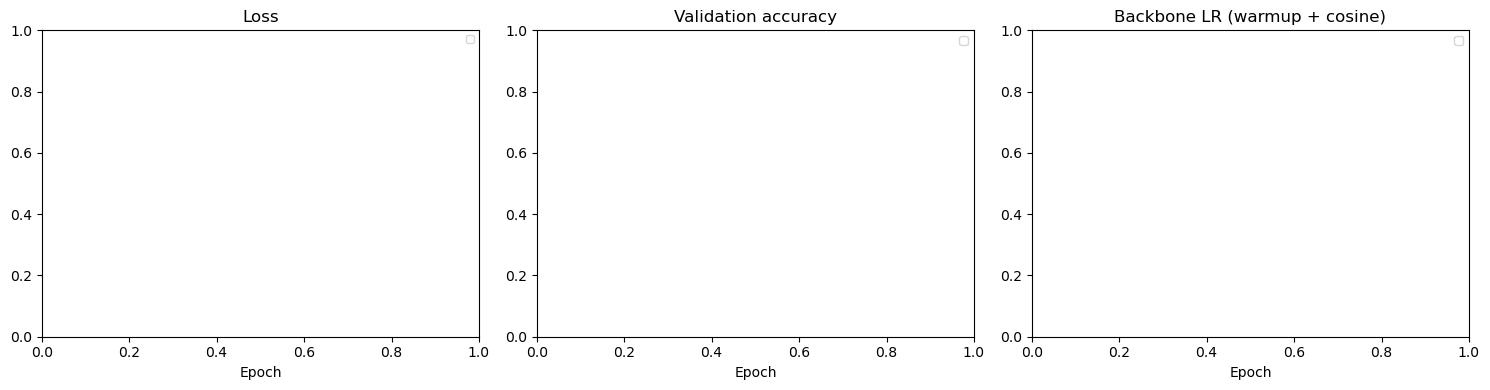

In [11]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
loss_axis, accuracy_axis, lr_axis = axes

for name, (_, score, _, hist) in trained_models.items():
    if hist is None or len(hist) == 0:
        continue
    loss_axis.plot(hist['epoch'], hist['train_loss'], label=f'{name} train')
    loss_axis.plot(hist['epoch'], hist['validation_loss'], linestyle='--', label=f'{name} val')
    accuracy_axis.plot(hist['epoch'], hist['validation_accuracy'], label=f'{name} ({100 * score:.1f}%)')
    lr_axis.plot(hist['epoch'], hist['backbone_lr'], label=f'{name} backbone')

loss_axis.set_title('Loss')
loss_axis.set_xlabel('Epoch')
loss_axis.legend(fontsize=7)
accuracy_axis.set_title('Validation accuracy')
accuracy_axis.set_xlabel('Epoch')
accuracy_axis.legend(fontsize=8)
lr_axis.set_title('Backbone LR (warmup + cosine)')
lr_axis.set_xlabel('Epoch')
lr_axis.legend(fontsize=8)
figure.tight_layout()
plt.show()


## Validation mistakes

Here I load the best checkpoint and look at the confusion matrix / per-class accuracy on the validation set. That tells me which classes are still getting mixed up.


Loaded: [redacted-path]


Loaded models: ['checkpoint']


Validation accuracy: 40.73%  (578/1419)

Per-class accuracy:


,class,support,correct,accuracy
0,birds,463,36,0.077754
1,bottles,75,62,0.826667
2,breads,65,64,0.984615
3,butterflies,56,56,1.000000
4,cakes,56,39,0.696429
5,cats,0,0,0.000000
6,chickens,2,0,0.000000
7,cows,0,0,0.000000
8,dogs,0,0,0.000000
9,ducks,0,0,0.000000


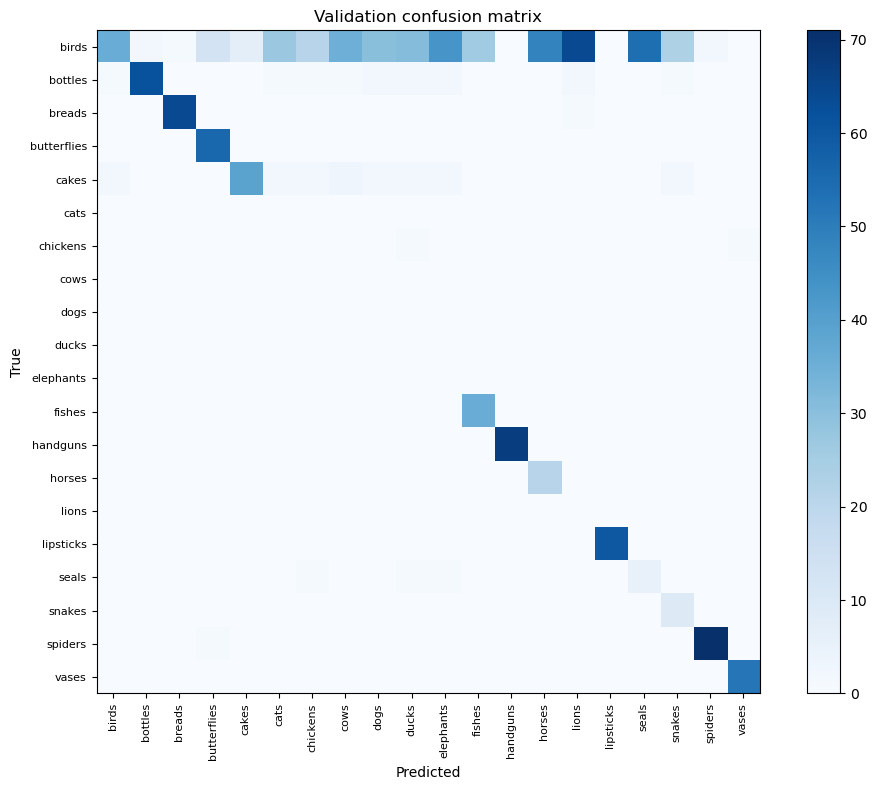


5 worst-performing classes:
  ducks         acc=0.00%  (0/0)  most often confused with: (no mistakes on val) (0)
  lions         acc=0.00%  (0/0)  most often confused with: (no mistakes on val) (0)
  elephants     acc=0.00%  (0/0)  most often confused with: (no mistakes on val) (0)
  dogs          acc=0.00%  (0/0)  most often confused with: (no mistakes on val) (0)
  cows          acc=0.00%  (0/0)  most often confused with: (no mistakes on val) (0)


In [12]:
try:
    from sklearn.metrics import confusion_matrix
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn'])
    from sklearn.metrics import confusion_matrix

# Try single checkpoint first, then ensemble file.
_diag_candidates = [
    ROOT / 'convnext_tiny_best.pt',
    ROOT / 'convnext_part3_ensemble.pt',
]
diag_ckpt_path = next((p for p in _diag_candidates if p.is_file()), None)
if diag_ckpt_path is None:
    raise FileNotFoundError(
        'Need convnext_tiny_best.pt or convnext_part3_ensemble.pt in the working directory.'
    )

loaded = torch.load(diag_ckpt_path, map_location=device, weights_only=False)
print('Loaded:', diag_ckpt_path)


def _state_dicts_from_checkpoint(obj: dict) -> list[tuple[str, dict]]:
    """List of (name, state_dict) from the checkpoint file."""
    if 'model_state_dict' in obj:
        return [('checkpoint', obj['model_state_dict'])]
    if 'models' in obj:
        items = []
        for name, info in obj['models'].items():
            items.append((name, info['state_dict']))
        return items
    raise KeyError(f'Unrecognised checkpoint keys: {list(obj.keys())}')


def _build_model_for_state(state_dict: dict) -> nn.Module:
    """Build a model that matches the checkpoint weights."""
    keys = list(state_dict.keys())
    if any(k.startswith('backbone.classifier') or '.classifier.' in k for k in keys):
        from torchvision import models as _models
        from torchvision.models import ConvNeXt_Tiny_Weights

        class _TorchvisionConvNeXt(nn.Module):
            def __init__(self, num_classes: int, dropout: float = 0.3):
                super().__init__()
                backbone = _models.convnext_tiny(weights=None)
                in_features = backbone.classifier[2].in_features
                backbone.classifier[2] = nn.Sequential(
                    nn.Dropout(p=dropout),
                    nn.Linear(in_features, num_classes),
                )
                self.backbone = backbone

            def forward(self, x):
                return self.backbone(x)

        model = _TorchvisionConvNeXt(num_classes=len(class_names)).to(device)
        model.load_state_dict(state_dict)
        return model

    # timm / current TimmClassifier layout
    model = make_model()
    model.load_state_dict(state_dict)
    return model


@torch.inference_mode()
def _collect_val_predictions(models: list[nn.Module]):
    for m in models:
        m.eval()
    all_true, all_pred = [], []
    for images, labels in validation_loader:
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        labels = labels.to(device=device, dtype=torch.long, non_blocking=True)
        with autocast(device_type='cuda', enabled=(device.type == 'cuda')):
            probs = None
            for m in models:
                logits = m(images)
                p = torch.softmax(logits.float(), dim=1)
                probs = p if probs is None else probs + p
            probs = probs / len(models)
        preds = probs.argmax(dim=1)
        all_true.extend(labels.cpu().tolist())
        all_pred.extend(preds.cpu().tolist())
    return np.asarray(all_true), np.asarray(all_pred)


state_items = _state_dicts_from_checkpoint(loaded)
diag_models = [_build_model_for_state(sd) for _, sd in state_items]
print('Loaded models:', [name for name, _ in state_items])

y_true, y_pred = _collect_val_predictions(diag_models)
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
per_class_total = cm.sum(axis=1)
per_class_correct = np.diag(cm)
per_class_acc = np.divide(
    per_class_correct,
    per_class_total,
    out=np.zeros(len(class_names), dtype=np.float64),
    where=per_class_total > 0,
)

overall_acc = float((y_true == y_pred).mean())
print(f'Validation accuracy: {overall_acc:.2%}  ({(y_true == y_pred).sum()}/{len(y_true)})')
print('\nPer-class accuracy:')
per_class_table = pd.DataFrame({
    'class': class_names,
    'support': per_class_total,
    'correct': per_class_correct,
    'accuracy': per_class_acc,
}).sort_values('accuracy')
display(per_class_table.sort_values('class').reset_index(drop=True))

# plot confusion matrix
figure, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(cm, interpolation='nearest', cmap='Blues')
axis.set_title('Validation confusion matrix')
figure.colorbar(image, ax=axis, fraction=0.046)
tick_marks = np.arange(len(class_names))
axis.set_xticks(tick_marks)
axis.set_yticks(tick_marks)
axis.set_xticklabels(class_names, rotation=90, fontsize=8)
axis.set_yticklabels(class_names, fontsize=8)
axis.set_xlabel('Predicted')
axis.set_ylabel('True')
figure.tight_layout()
plt.show()

# worst 5 classes and what they get confused with
worst = per_class_table.head(5)
print('\n5 worst-performing classes:')
for _, row in worst.iterrows():
    class_idx = class_names.index(row['class'])
    row_counts = cm[class_idx].copy()
    row_counts[class_idx] = 0  # ignore correct predictions
    if row_counts.sum() == 0:
        confusable = '(no mistakes on val)'
        confusable_n = 0
    else:
        confusable_idx = int(row_counts.argmax())
        confusable = class_names[confusable_idx]
        confusable_n = int(row_counts[confusable_idx])
    print(
        f"  {row['class']:12s}  acc={row['accuracy']:.2%}  "
        f"({int(row['correct'])}/{int(row['support'])})  "
        f"most often confused with: {confusable} ({confusable_n})"
    )


## 6. Building `submission.csv`

I pick the best of the soups vs the softmax ensemble on validation (with 4-view TTA), then write predictions for the test set using the same 4 TTA views.


In [13]:
@torch.inference_mode()
def predict_logits(model, loader):
    model.eval()
    all_ids = []
    all_logits = []
    for batch in loader:
        # test loaders yield (image, id); val loaders yield (image, label)
        images, meta = batch
        images = images.to(device=device, dtype=torch.float32, non_blocking=True)
        with autocast(device_type='cuda', enabled=(device.type == 'cuda')):
            logits = model(images)
        all_logits.append(logits.float().cpu())
        all_ids.extend(meta.tolist())
    return all_ids, torch.cat(all_logits, dim=0)


def predict_probs_with_tta(model, loaders):
    """Average softmax over the TTA loaders."""
    view_probs = []
    ref_ids = None
    for loader in loaders:
        ids, logits = predict_logits(model, loader)
        if ref_ids is None:
            ref_ids = ids
        elif ids != ref_ids:
            raise RuntimeError('TTA loaders returned mismatched ID/label order.')
        view_probs.append(torch.softmax(logits, dim=1))
    probs = torch.stack(view_probs, dim=0).mean(dim=0)
    return ref_ids, probs


TEST_TTA_LOADERS = [test_loader, test_loader_hflip, test_loader_crop, test_loader_rotate]
VAL_TTA_LOADERS_2 = [validation_loader, validation_loader_hflip]
VAL_TTA_LOADERS_4 = [
    validation_loader,
    validation_loader_hflip,
    validation_loader_crop,
    validation_loader_rotate,
]


def ensemble_val_accuracy(loaders, members, tag: str) -> float:
    labels_ref = None
    member_probs = []
    for name, (mdl, score, *_) in members:
        ids_or_labels, probs = predict_probs_with_tta(mdl, loaders)
        if labels_ref is None:
            labels_ref = torch.tensor(ids_or_labels, dtype=torch.long)
        member_probs.append(probs)
        print(f'  [{tag}] {name}: selected val={100 * score:.2f}%')
    probs = torch.stack(member_probs, dim=0).mean(dim=0)
    preds = probs.argmax(dim=1)
    acc = float((preds == labels_ref).float().mean())
    print(f'[{tag}] Ensemble validation accuracy: {acc:.2%}')
    return acc


print(f'Submission mode from soup comparison: {submission_mode}')

# Optional: still report 2-view vs 4-view softmax ensemble for reference
if submission_mode == 'softmax_ensemble_top2' or submission_mode == 'softmax_ensemble':
    print('Reference — softmax ensemble TTA on validation:')
    val_acc_2 = ensemble_val_accuracy(VAL_TTA_LOADERS_2, ensemble_members, 'TTA-2 (orig+hflip)')
    val_acc_4 = ensemble_val_accuracy(VAL_TTA_LOADERS_4, ensemble_members, 'TTA-4 (orig+hflip+crop+rot10)')
    print(
        f'TTA-4 vs TTA-2: {100 * (val_acc_4 - val_acc_2):+.2f}% '
        f'({100 * val_acc_2:.2f}% -> {100 * val_acc_4:.2f}%)'
    )

# --- Build test probabilities with the winning method ---
if submission_mode.startswith('soup') or submission_mode == 'greedy_soup':
    if final_soup_model is None:
        raise RuntimeError(f'submission_mode={submission_mode} but final_soup_model is None')
    predicted_ids, ensemble_probs = predict_probs_with_tta(final_soup_model, TEST_TTA_LOADERS)
    print(f'Test predictions from {submission_mode} (single souped weights + 4-view TTA)')
else:
    # Softmax ensemble over ensemble_members
    ensemble_probs = None
    predicted_ids = None
    for name, (mdl, score, *_) in ensemble_members:
        ids, probs = predict_probs_with_tta(mdl, TEST_TTA_LOADERS)
        print(f'Test TTA-4 probs from {name}: selected val={100 * score:.2f}%')
        if ensemble_probs is None:
            ensemble_probs = probs
            predicted_ids = ids
        else:
            if ids != predicted_ids:
                raise RuntimeError('Ensemble members returned mismatched ID order.')
            ensemble_probs = ensemble_probs + probs
    ensemble_probs = ensemble_probs / len(ensemble_members)
    print(f'Test predictions from softmax ensemble over {[n for n, _ in ensemble_members]}')

predicted_indices = ensemble_probs.argmax(dim=1).tolist()

prediction_frame = pd.DataFrame({
    'ID': predicted_ids,
    'Label': [class_names[index] for index in predicted_indices],
})
if prediction_frame['ID'].duplicated().any():
    raise RuntimeError('Predictions contain duplicate IDs.')
if set(prediction_frame['Label']) - set(EXPECTED_CLASS_NAMES):
    raise RuntimeError('Predictions contain an invalid class label.')

submission = submission_template[['ID']].merge(
    prediction_frame, on='ID', how='left', validate='one_to_one'
)
if submission.columns.tolist() != ['ID', 'Label']:
    raise RuntimeError('Submission must contain exactly ID,Label.')
if len(submission) != EXPECTED_TEST_IMAGES or submission['Label'].isna().any():
    raise RuntimeError('Submission rows do not match the test set.')
if submission['ID'].tolist() != list(range(EXPECTED_TEST_IMAGES)):
    raise RuntimeError('Submission IDs are not ordered from 0 to 11680.')

label_counts = submission['Label'].value_counts()
print('\nPredicted label distribution:')
display(label_counts.sort_index())
max_share = float(label_counts.max() / len(submission))
print(f'Max class share: {max_share:.1%}')
if max_share > 0.20:
    print('Warning: one class dominates the predictions — worth checking before submit.')

SUBMISSION_PATH = ROOT / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
print('\nSubmission:', SUBMISSION_PATH)
print('Rows:', len(submission))
print(f'Method: {submission_mode} + 4-view TTA')
display(submission.head())


Submission mode from soup comparison: greedy_soup


Test predictions from greedy_soup (single souped weights + 4-view TTA)

Predicted label distribution:


Label
birds           122
bottles         223
breads          186
butterflies     711
cakes           271
cats            954
chickens        783
cows           1017
dogs            710
ducks           328
elephants       710
fishes          542
handguns        315
horses          783
lions          1654
lipsticks       373
seals           256
snakes          187
spiders         985
vases           571
Name: count, dtype: int64

Max class share: 14.2%

Submission: [redacted-path]
Rows: 11681
Method: greedy_soup + 4-view TTA


,ID,Label
0,0,birds
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


## 7. What I submit

The previous cell writes `submission.csv`. On Colab the next cell downloads it (and the checkpoints).

For Kaggle I upload `submission.csv` under **Submit Predictions** (not the empty `my_solution.csv`).

In [14]:
print('Submission saved at:', SUBMISSION_PATH if 'SUBMISSION_PATH' in globals() else '(not created yet)')

if IN_COLAB:
    from google.colab import files
    to_download = []
    for p in [
        ROOT / 'submission.csv',
        ROOT / 'convnextv2_tiny_best.pt',
        ROOT / 'convnextv2_part3_ensemble.pt',
    ]:
        if p.is_file():
            to_download.append(p)
    if not to_download:
        print('Nothing to download yet — run training + submission cells first.')
    else:
        print('Downloading from Colab:')
        for p in to_download:
            print(' ', p)
            files.download(str(p))
else:
    print('Not in Colab — files are already on disk under', ROOT)


Submission saved at: [redacted-path]
Not in Colab — files are already on disk under [redacted-path]
